# Занятие 10. Сиамские сети: сравнение изображений (PyTorch)
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Загрузим набор данных AT&T Faces (ORL) (https://git-disl.github.io/GTDLBench/datasets/att_face_dataset/) -- 40 человек по 10 фотографий (9 в папке `Training`, 1 в папке `Testing`).
2. Сформируем обучающие и проверочные пары «похожий / непохожий».
3. Реализуем сиамскую сеть с общими весами двух ветвей.
4. Обучим сеть с использованием контрастной функции потерь (contrastive loss).
5. Визуализируем процесс обучения и итоговое пространство эмбеддингов (несколько графиков, учитывая сложность темы для восприятия).
6. Проверим сеть на паре изображений, не участвовавших в обучении.

**Набор данных:** AT&T Database of Faces (ORL), вариант с готовым разбиением на `Training` и `Testing`.

![Датасет](https://git-disl.github.io/GTDLBench/figures/faces.gif)

---
## Шаг 1. Импорт библиотек

In [1]:
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cpu')
print(f'Устройство вычислений: {device}')

Устройство вычислений: cpu


---
## Шаг 2. Структура набора данных AT&T Faces

Набор данных уже разделён на обучающую и тестовую части. Разместите его в папке `./att_faces/`:

- `att_faces/Training/s1 ... s40` -- по одной папке на человека, в каждой 9 изображений `1.pgm ... 9.pgm`;
- `att_faces/Testing/s1 ... s40` -- по одной папке на человека, в каждой одно изображение; в папке `s{k}` оно называется `{k}.pgm` (например, `Testing/s3/3.pgm`).

Итого 40 человек x 10 изображений = 360 обучающих + 40 тестовых. Формат PGM, оттенки серого, 92x112 пикселей.
Тестовые изображения в обучении не участвуют.

In [2]:
from pathlib import Path

DATA_DIR = Path('./att_faces')
TRAIN_DIR = DATA_DIR / 'Training'
TEST_DIR = DATA_DIR / 'Testing'
N_PEOPLE = 40
N_TRAIN_PER_PERSON = 9

n_train = sum(len(list((TRAIN_DIR / f's{p}').glob('*.pgm'))) for p in range(1, N_PEOPLE + 1))
n_test = sum(len(list((TEST_DIR / f's{p}').glob('*.pgm'))) for p in range(1, N_PEOPLE + 1))
print(f'Обучающих изображений: {n_train} (ожидается {N_PEOPLE * N_TRAIN_PER_PERSON})')
print(f'Тестовых изображений: {n_test} (ожидается {N_PEOPLE})')

Обучающих изображений: 360 (ожидается 360)
Тестовых изображений: 40 (ожидается 40)


---
## Шаг 3. Формирование обучающих и проверочных пар («похожий / непохожий»)

Сиамская сеть обучается на парах изображений с меткой: 1 -- на снимках один и тот же человек, 0 -- разные люди.
Используем готовое разбиение набора данных.

- **Обучающие пары** строятся только из `Training`: похожая пара -- два разных изображения одного человека, непохожая -- изображения двух разных людей. Количество похожих и непохожих пар одинаково.
- **Проверочные пары** строятся с участием `Testing`. В `Testing` только одно изображение на человека, поэтому тестовое изображение сопоставляется с обучающим изображением того же человека (метка 1) или другого человека (метка 0). Для каждого из 40 человек создаётся одна похожая и одна непохожая пара.

In [3]:
IMG_SIZE = 64

def load_face_image(path):
    img = Image.open(path).convert('L').resize((IMG_SIZE, IMG_SIZE))
    return np.array(img, dtype=np.float32) / 255.0


person_ids = list(range(1, N_PEOPLE + 1))
train_images_idx = list(range(1, N_TRAIN_PER_PERSON + 1))   # 1.pgm ... 9.pgm


def train_path(pid, img_idx):
    return TRAIN_DIR / f's{pid}' / f'{img_idx}.pgm'


def test_path(pid):
    return TEST_DIR / f's{pid}' / f'{pid}.pgm'


def build_train_pairs(n_pairs_per_type=300):
    """Пары (путь1, путь2, метка) из Training; метка=1 -- один и тот же человек."""
    pairs = []
    for _ in range(n_pairs_per_type):
        pid = np.random.choice(person_ids)
        i, j = np.random.choice(train_images_idx, size=2, replace=False)
        pairs.append((train_path(pid, i), train_path(pid, j), 1))
    for _ in range(n_pairs_per_type):
        pid1, pid2 = np.random.choice(person_ids, size=2, replace=False)
        i = np.random.choice(train_images_idx)
        j = np.random.choice(train_images_idx)
        pairs.append((train_path(pid1, i), train_path(pid2, j), 0))
    np.random.shuffle(pairs)
    return pairs


def build_val_pairs():
    """Пары (тестовое изображение, обучающее изображение, метка)."""
    pairs = []
    for pid in person_ids:
        same = np.random.choice(train_images_idx)
        pairs.append((test_path(pid), train_path(pid, same), 1))
        other = np.random.choice([p for p in person_ids if p != pid])
        diff = np.random.choice(train_images_idx)
        pairs.append((test_path(pid), train_path(other, diff), 0))
    np.random.shuffle(pairs)
    return pairs


train_pairs = build_train_pairs(n_pairs_per_type=300)
val_pairs = build_val_pairs()

print(f'Обучающих пар: {len(train_pairs)} (300 положительных и 300 отрицательных)')
print(f'Проверочных пар: {len(val_pairs)} (40 положительных и 40 отрицательных)')

Обучающих пар: 600 (300 положительных и 300 отрицательных)
Проверочных пар: 80 (40 положительных и 40 отрицательных)


---
## Шаг 4. Класс набора данных для пар изображений

In [4]:
class SiamesePairDataset(Dataset):
    """Набор данных пар изображений для обучения сиамской сети."""

    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        path1, path2, label = self.pairs[idx]
        img1 = load_face_image(path1)
        img2 = load_face_image(path2)
        img1_t = torch.from_numpy(img1).unsqueeze(0)
        img2_t = torch.from_numpy(img2).unsqueeze(0)
        return img1_t, img2_t, torch.tensor(label, dtype=torch.float32)


try:
    train_dataset = SiamesePairDataset(train_pairs)
    val_dataset = SiamesePairDataset(val_pairs)
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
    _ = train_dataset[0]; _ = val_dataset[0]   # проверка, что файлы читаются
    data_ready = True
    print('Загрузчики данных готовы.')
except Exception as e:
    print(f'ВНИМАНИЕ: данные не найдены ({e}). Проверьте структуру Training/Testing (Шаг 2).')
    data_ready = False

Загрузчики данных готовы.


---
## Шаг 5. Визуализация примеров пар (похожие и непохожие)

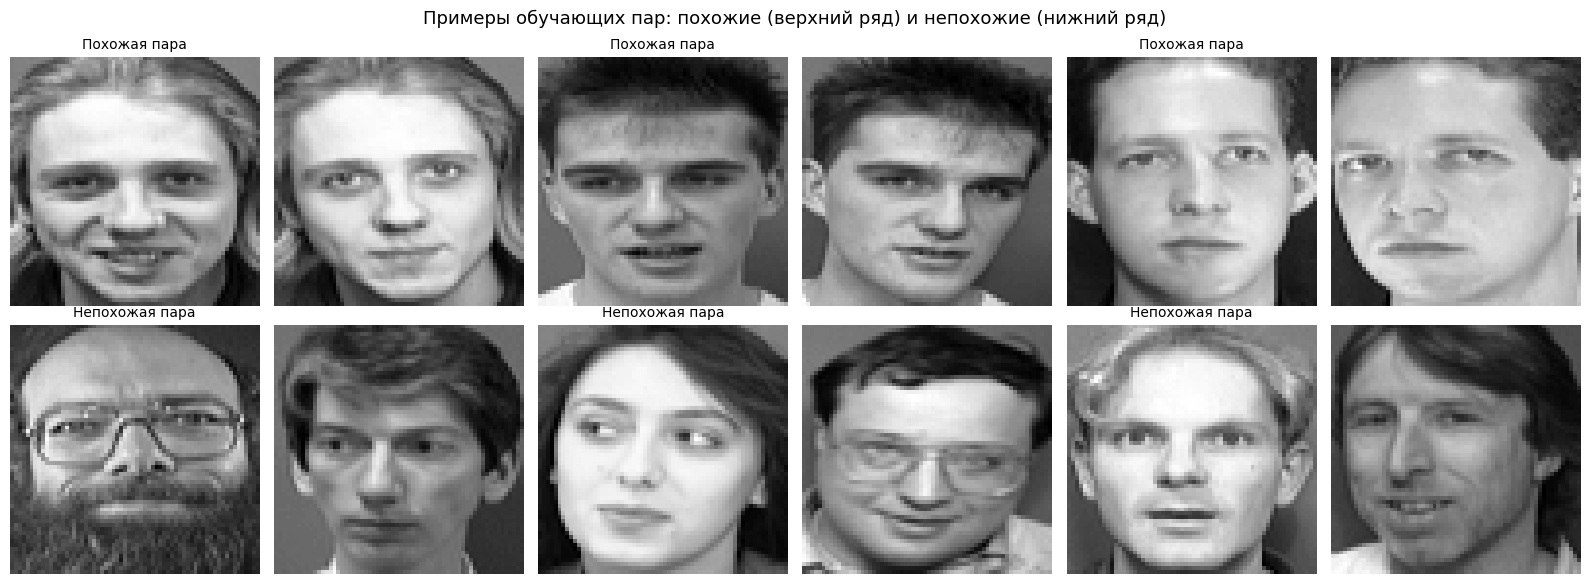

In [5]:
if data_ready:
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    shown_pos, shown_neg = 0, 0
    for path1, path2, label in train_pairs:
        if label == 1 and shown_pos < 3:
            row = 0; col = shown_pos * 2
            axes[row, col].imshow(load_face_image(path1), cmap='gray'); axes[row, col].axis('off')
            axes[row, col+1].imshow(load_face_image(path2), cmap='gray'); axes[row, col+1].axis('off')
            axes[row, col].set_title('Похожая пара', fontsize=10)
            shown_pos += 1
        elif label == 0 and shown_neg < 3:
            row = 1; col = shown_neg * 2
            axes[row, col].imshow(load_face_image(path1), cmap='gray'); axes[row, col].axis('off')
            axes[row, col+1].imshow(load_face_image(path2), cmap='gray'); axes[row, col+1].axis('off')
            axes[row, col].set_title('Непохожая пара', fontsize=10)
            shown_neg += 1
        if shown_pos >= 3 and shown_neg >= 3:
            break
    plt.suptitle('Примеры обучающих пар: похожие (верхний ряд) и непохожие (нижний ряд)', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 6. Архитектура сиамской сети

Обе ветви сети используют один и тот же экземпляр подсети (общие веса) --
ключевое свойство сиамской архитектуры.

In [6]:
class EmbeddingNet(nn.Module):
    """Единая подсеть ('ветвь') сиамской сети, преобразующая изображение в вектор-эмбеддинг."""

    def __init__(self, embedding_dim=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 5), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.flatten_dim = 64 * 5 * 5
        self.fc = nn.Sequential(
            nn.Linear(self.flatten_dim, 128), nn.ReLU(),
            nn.Linear(128, embedding_dim),
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class SiameseNetwork(nn.Module):
    """Сиамская сеть: две ветви с общими весами (один и тот же embedding_net)."""

    def __init__(self, embedding_dim=32):
        super().__init__()
        self.embedding_net = EmbeddingNet(embedding_dim)  # единственный экземпляр подсети

    def forward(self, x1, x2):
        emb1 = self.embedding_net(x1)  # общие веса применяются к первому изображению
        emb2 = self.embedding_net(x2)  # и ко второму изображению -- та же подсеть
        return emb1, emb2


siamese_model = SiameseNetwork(embedding_dim=32).to(device)
num_params = sum(p.numel() for p in siamese_model.parameters())
print(f'Число обучаемых параметров (общих для обеих ветвей): {num_params:,}')

Число обучаемых параметров (общих для обеих ветвей): 240,800


---
## Шаг 7. Контрастная функция потерь

In [7]:
class ContrastiveLoss(nn.Module):
    """Контрастная функция потерь: формула (2) теоретического материала."""

    def __init__(self, margin=2.0):
        super().__init__()
        self.margin = margin

    def forward(self, emb1, emb2, label):
        distance = F.pairwise_distance(emb1, emb2)
        loss_similar = label * distance.pow(2)
        loss_dissimilar = (1 - label) * torch.clamp(self.margin - distance, min=0.0).pow(2)
        return (loss_similar + loss_dissimilar).mean(), distance


criterion = ContrastiveLoss(margin=2.0)
print('Контрастная функция потерь определена, отступ (margin) = 2.0')

Контрастная функция потерь определена, отступ (margin) = 2.0


---
## Шаг 8. Цикл обучения с подробным отслеживанием метрик

In [8]:
if data_ready:
    optimizer = torch.optim.Adam(siamese_model.parameters(), lr=5e-4)
    NUM_EPOCHS = 20
    history = {'train_loss': [], 'val_loss': [], 'val_accuracy': []}
    DECISION_THRESHOLD = 1.0  # порог расстояния для принятия решения 'похожи/не похожи'

    for epoch in range(NUM_EPOCHS):
        siamese_model.train()
        train_loss_sum = 0.0
        for img1, img2, label in train_loader:
            img1, img2, label = img1.to(device), img2.to(device), label.to(device)
            optimizer.zero_grad()
            emb1, emb2 = siamese_model(img1, img2)
            loss, _ = criterion(emb1, emb2, label)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * img1.size(0)
        train_loss = train_loss_sum / len(train_dataset)

        siamese_model.eval()
        val_loss_sum, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for img1, img2, label in val_loader:
                img1, img2, label = img1.to(device), img2.to(device), label.to(device)
                emb1, emb2 = siamese_model(img1, img2)
                loss, distance = criterion(emb1, emb2, label)
                val_loss_sum += loss.item() * img1.size(0)
                predicted_similar = (distance < DECISION_THRESHOLD).float()
                correct += (predicted_similar == label).sum().item()
                total += label.size(0)

        val_loss = val_loss_sum / len(val_dataset)
        val_acc = correct / total
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        print(f'Эпоха {epoch+1:2d}/{NUM_EPOCHS} | потери(обуч.)={train_loss:.4f} | '
              f'потери(провер.)={val_loss:.4f} | точность(провер.)={val_acc:.4f}')

Эпоха  1/20 | потери(обуч.)=1.0880 | потери(провер.)=0.4785 | точность(провер.)=0.8125
Эпоха  2/20 | потери(обуч.)=0.5046 | потери(провер.)=0.5052 | точность(провер.)=0.8625
Эпоха  3/20 | потери(обуч.)=0.4270 | потери(провер.)=0.3888 | точность(провер.)=0.9000
Эпоха  4/20 | потери(обуч.)=0.3660 | потери(провер.)=0.3595 | точность(провер.)=0.8750
Эпоха  5/20 | потери(обуч.)=0.3093 | потери(провер.)=0.3419 | точность(провер.)=0.8875
Эпоха  6/20 | потери(обуч.)=0.2756 | потери(провер.)=0.3501 | точность(провер.)=0.9000
Эпоха  7/20 | потери(обуч.)=0.2474 | потери(провер.)=0.3261 | точность(провер.)=0.9125
Эпоха  8/20 | потери(обуч.)=0.2180 | потери(провер.)=0.3354 | точность(провер.)=0.9125
Эпоха  9/20 | потери(обуч.)=0.1886 | потери(провер.)=0.3370 | точность(провер.)=0.9000
Эпоха 10/20 | потери(обуч.)=0.1751 | потери(провер.)=0.2986 | точность(провер.)=0.9250
Эпоха 11/20 | потери(обуч.)=0.1448 | потери(провер.)=0.3096 | точность(провер.)=0.9000
Эпоха 12/20 | потери(обуч.)=0.1356 | потери

---
## Шаг 9. Визуализация кривых обучения

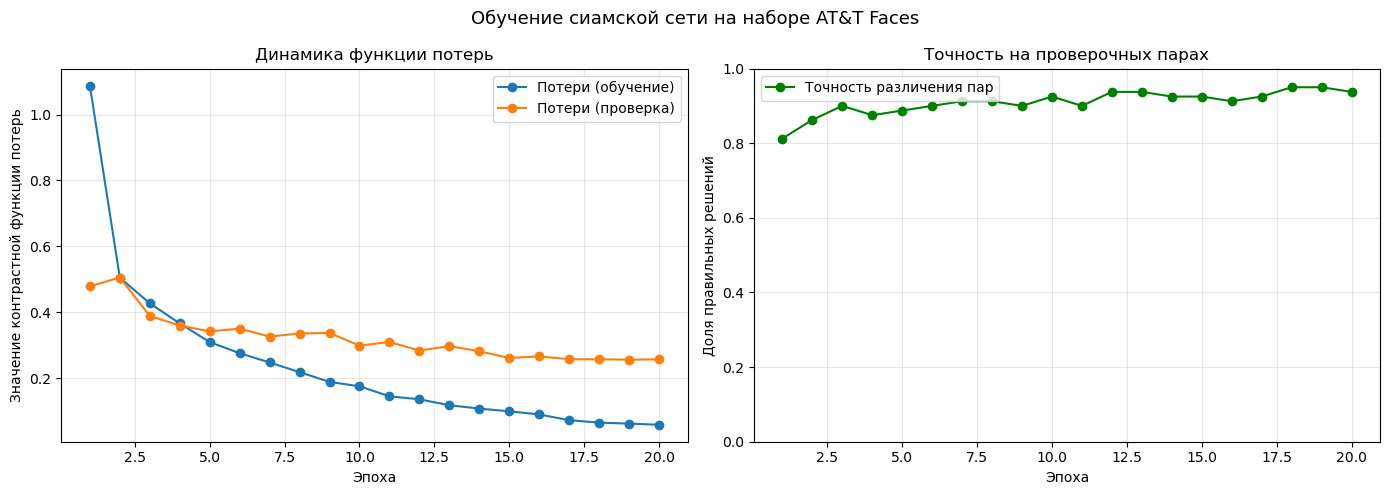

In [9]:
if data_ready:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs_range = range(1, NUM_EPOCHS + 1)

    axes[0].plot(epochs_range, history['train_loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(epochs_range, history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение контрастной функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_range, history['val_accuracy'], label='Точность различения пар', marker='o', color='green')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Доля правильных решений')
    axes[1].set_title('Точность на проверочных парах'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение сиамской сети на наборе AT&T Faces', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 10. Распределение расстояний: похожие против непохожих пар

Важная визуализация для понимания качества метрического обучения: должно быть
видно чёткое разделение расстояний для двух типов пар.

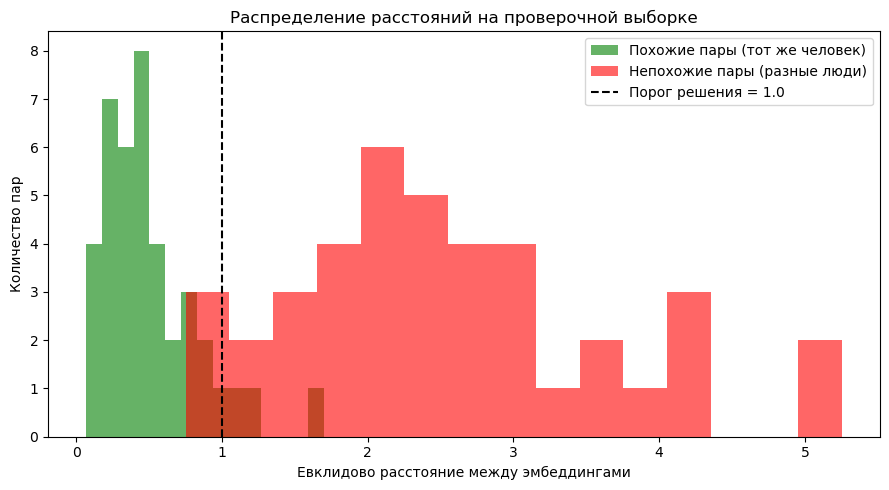

Среднее расстояние для похожих пар: 0.511
Среднее расстояние для непохожих пар: 2.552


In [10]:
if data_ready:
    siamese_model.eval()
    distances_similar, distances_dissimilar = [], []
    with torch.no_grad():
        for img1, img2, label in val_loader:
            emb1, emb2 = siamese_model(img1.to(device), img2.to(device))
            dist = F.pairwise_distance(emb1, emb2).numpy()
            for d, l in zip(dist, label.numpy()):
                if l == 1:
                    distances_similar.append(d)
                else:
                    distances_dissimilar.append(d)

    plt.figure(figsize=(9, 5))
    plt.hist(distances_similar, bins=15, alpha=0.6, label='Похожие пары (тот же человек)', color='green')
    plt.hist(distances_dissimilar, bins=15, alpha=0.6, label='Непохожие пары (разные люди)', color='red')
    plt.axvline(DECISION_THRESHOLD, color='black', linestyle='--', label=f'Порог решения = {DECISION_THRESHOLD}')
    plt.xlabel('Евклидово расстояние между эмбеддингами')
    plt.ylabel('Количество пар')
    plt.title('Распределение расстояний на проверочной выборке')
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f'Среднее расстояние для похожих пар: {np.mean(distances_similar):.3f}')
    print(f'Среднее расстояние для непохожих пар: {np.mean(distances_dissimilar):.3f}')

---
## Шаг 11. Визуализация пространства эмбеддингов (PCA и t-SNE)

Построим эмбеддинги отдельных изображений (не пар) для первых 10 человек: 9 обучающих изображений из `Training`
(кружки) и тестовое изображение из `Testing` (звезда). Размерность снижается до двух координат для визуализации. Если сеть обучена хорошо, звезда лежит рядом с кружками своего цвета.

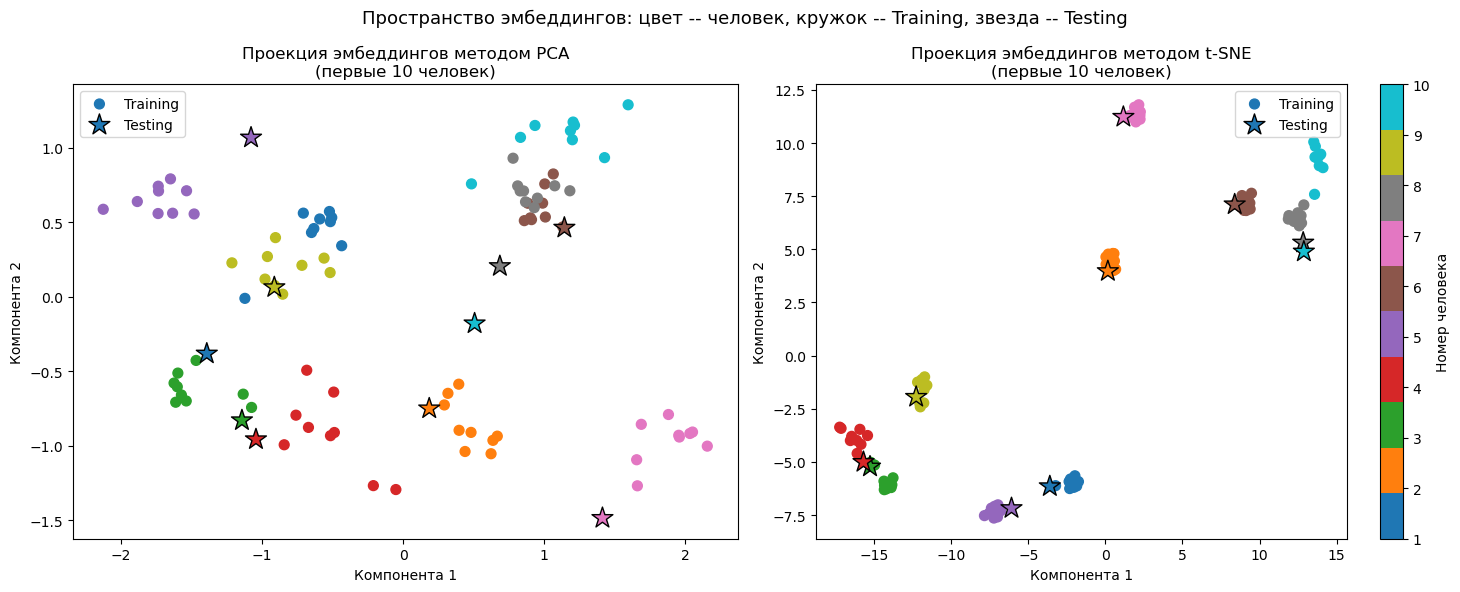

Ожидаемый результат: точки одного цвета (один человек) образуют компактные,
разделённые скопления; тестовая звезда находится внутри скопления своего цвета.


In [11]:
if data_ready:
    subset_people = person_ids[:10]   # первые 10 человек для читаемости
    all_embeddings, all_labels, all_is_test = [], [], []
    siamese_model.eval()
    with torch.no_grad():
        for pid in subset_people:
            items = [(train_path(pid, i), False) for i in train_images_idx] + [(test_path(pid), True)]
            for path, flag in items:
                img_t = torch.from_numpy(load_face_image(path)).unsqueeze(0).unsqueeze(0).to(device)
                all_embeddings.append(siamese_model.embedding_net(img_t).numpy().flatten())
                all_labels.append(pid)
                all_is_test.append(flag)

    all_embeddings = np.array(all_embeddings)
    all_labels = np.array(all_labels)
    all_is_test = np.array(all_is_test)

    emb_pca = PCA(n_components=2).fit_transform(all_embeddings)
    emb_tsne = TSNE(n_components=2, perplexity=15, random_state=SEED, init='pca').fit_transform(all_embeddings)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, emb, name in [(axes[0], emb_pca, 'PCA'), (axes[1], emb_tsne, 't-SNE')]:
        sc = ax.scatter(emb[~all_is_test, 0], emb[~all_is_test, 1], c=all_labels[~all_is_test],
                        cmap='tab10', s=50, label='Training')
        ax.scatter(emb[all_is_test, 0], emb[all_is_test, 1], c=all_labels[all_is_test],
                   cmap='tab10', s=250, marker='*', edgecolors='black', label='Testing')
        ax.set_title(f'Проекция эмбеддингов методом {name}\n(первые 10 человек)')
        ax.set_xlabel('Компонента 1'); ax.set_ylabel('Компонента 2'); ax.legend()
    plt.colorbar(sc, ax=axes[1], label='Номер человека')
    plt.suptitle('Пространство эмбеддингов: цвет -- человек, кружок -- Training, звезда -- Testing', fontsize=13)
    plt.tight_layout()
    plt.show()

    print('Ожидаемый результат: точки одного цвета (один человек) образуют компактные,')
    print('разделённые скопления; тестовая звезда находится внутри скопления своего цвета.')

---
## Шаг 12. Проверка на конкретной паре изображений

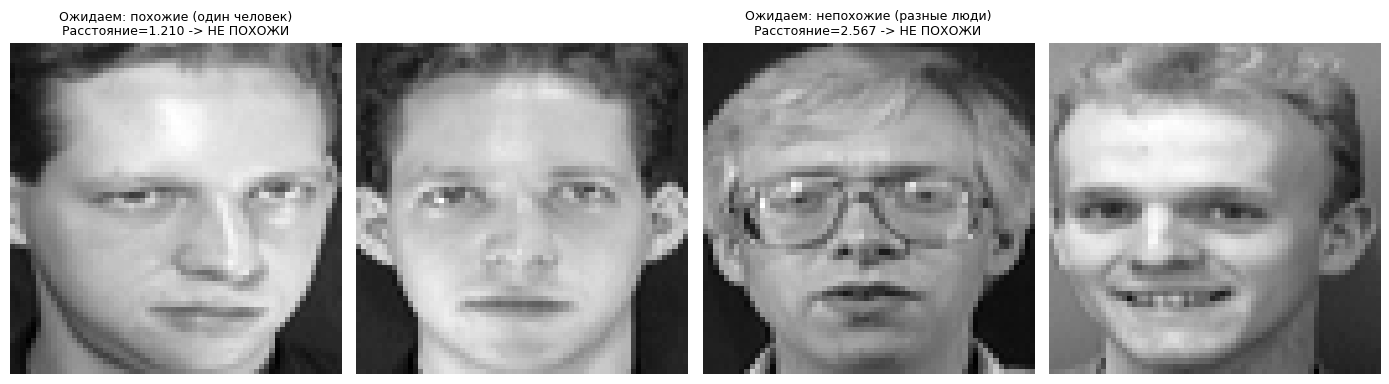

In [12]:
if data_ready:
    test_pairs_demo = [
        (test_path(1), train_path(1, 1), 'Ожидаем: похожие (один человек)'),
        (test_path(2), train_path(5, 1), 'Ожидаем: непохожие (разные люди)'),
    ]

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for i, (path1, path2, expectation) in enumerate(test_pairs_demo):
        img1, img2 = load_face_image(path1), load_face_image(path2)
        img1_t = torch.from_numpy(img1).unsqueeze(0).unsqueeze(0)
        img2_t = torch.from_numpy(img2).unsqueeze(0).unsqueeze(0)
        with torch.no_grad():
            emb1, emb2 = siamese_model(img1_t, img2_t)
            dist = F.pairwise_distance(emb1, emb2).item()
        verdict = 'ПОХОЖИ' if dist < DECISION_THRESHOLD else 'НЕ ПОХОЖИ'

        axes[i*2].imshow(img1, cmap='gray'); axes[i*2].axis('off')
        axes[i*2+1].imshow(img2, cmap='gray'); axes[i*2+1].axis('off')
        axes[i*2].set_title(f'{expectation}\nРасстояние={dist:.3f} -> {verdict}', fontsize=9)

    plt.tight_layout()
    plt.show()

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | AT&T Faces (ORL), 40 человек x 10 изображений: Training -- 9, Testing -- 1 |
| Формирование пар | Обучающие: 300 похожих + 300 непохожих из Training. Проверочные: 40 + 40 (тестовое изображение + обучающее) |
| Архитектура | Сиамская сеть, общие веса, эмбеддинг размерности 32 |
| Функция потерь | Контрастная функция потерь (contrastive loss), margin=2.0 |
| Визуализация | Кривые обучения, распределение расстояний, PCA/t-SNE проекции, демонстрация на конкретных парах |

---
## Домашнее задание

1. **Основное.** Реализуйте triplet loss (формула 3 теоретического материала) вместо контрастной функции потерь. Для этого потребуется изменить формирование обучающих данных: вместо пар нужно формировать тройки (якорь, положительный пример, отрицательный пример) из `Training`. Сравните итоговое разделение расстояний (аналог Шага 10) для двух функций потерь.

2. **Исследование порога решения.** Постройте график зависимости точности различения пар (как в Шаге 8) от значения DECISION_THRESHOLD, изменяя его от 0.2 до 3.0 с шагом 0.2. Определите оптимальное значение порога и объясните полученный результат с учётом распределения из Шага 10.

3. **Влияние размерности эмбеддинга.** Обучите три отдельные сиамские сети с embedding_dim = 8, 32 и 128 при одинаковых остальных условиях. Сравните итоговую точность и визуализацию пространства эмбеддингов (Шаг 11) для всех трёх вариантов. Как зависит качество и время обучения от размерности?

4. **(Дополнительно)** Проверьте способность сети к однократному обучению (one-shot learning): исключите одного человека из обучения (например, s40, обучаясь только на s1-s39) и проверьте, сможет ли сеть верно определить, что тестовое изображение `Testing/s40/40.pgm` и обучающее изображение из `Training/s40` принадлежат одному человеку, а `Testing/s40/40.pgm` и изображение любого другого человека -- разным людям.

5. **(Дополнительно)** Постройте матрицу расстояний размера 10x10 между эмбеддингами первых 10 человек (используя, например, первое изображение из `Training` каждого) и визуализируйте её в виде тепловой карты (`plt.imshow` с цветовой шкалой). Проанализируйте, есть ли пары людей, которых модель считает особенно похожими, и предположите возможные причины.